# Arquitectura multiagente: diseño, implementación y medición


Este notebook construye paso a paso un sistema de varios agentes de IA, lo compara con un agente único y mide su **calidad**, **costo**, **latencia**, **robustez** y **costo de coordinación**. Todo se implementa desde cero, sin frameworks, para que cada pieza sea visible.

**Caso guía.** La *Tostaduría Samán* (empresa **ficticia** de Cali) debe decidir su próxima inversión. Su información interna está en una pequeña base de conocimiento; los agentes la consultan con una herramienta de búsqueda y responden preguntas de negocio citando las fuentes.

**Cómo correrlo.**

- Se necesita una clave de **OpenRouter**: todas las llamadas van a modelos reales y el costo se mide en dólares reales.

| Sección | Contenido |
|---|---|
| 0 | Configuración, modelos y precios |
| 1 | Base de conocimiento y herramienta de búsqueda |
| 2 | Cliente LLM con trazas, reintentos y tope de gasto |
| 3 | Un agente genérico: el ciclo pensar → actuar → observar |
| 4 | Baseline: agente único |
| 5 | Diseño e implementación multiagente |
| 6 | Observabilidad: costo por agente y línea de tiempo |
| 7 | Evaluación: dataset, juez LLM y métricas |
| 8 | Experimento comparativo y frontera de Pareto |
| 9 | Optimización de costos |
| 10 | Ejercicios |
| 11 | Del código propio a los frameworks |

## 0. Configuración

Se instalan las dependencias. OpenRouter expone una API compatible con la de OpenAI, así que basta con el SDK `openai` apuntando a `https://openrouter.ai/api/v1`.

In [81]:
# Dependencias gestionadas con uv; ejecutar `uv sync` desde la carpeta del proyecto.

In [85]:
import os
from dotenv import load_dotenv, find_dotenv

print("Directorio actual (cwd):", os.getcwd())
ruta_env = find_dotenv(usecwd=True)
print("Ruta del .env encontrada:", ruta_env or "NO SE ENCONTRÓ")

load_dotenv(ruta_env)

Directorio actual (cwd): c:\Users\4616289\Desktop\multiagente
Ruta del .env encontrada: c:\Users\4616289\Desktop\multiagente\.env


True

In [88]:
import os
from dotenv import load_dotenv

print("cwd del kernel:", os.getcwd())
load_dotenv(r"C:\Users\4616289\Desktop\multiagente\.env", override=True)

OPENROUTER_API_KEY = os.getenv("OPENROUTER_API_KEY", "")
if not OPENROUTER_API_KEY:
    raise RuntimeError("Falta OPENROUTER_API_KEY en el archivo .env")
print("OPENROUTER_API_KEY: CARGADA")

cwd del kernel: c:\Users\4616289\Desktop\multiagente
OPENROUTER_API_KEY: CARGADA


La clave se lee de la variable `OPENROUTER_API_KEY` del archivo local `.env`. No conviene escribirla en el notebook si se va a compartir.

Los modelos se asignan **por rol**: esa es una de las decisiones de diseño más importantes para el costo.

In [ ]:
import os, json, time, asyncio, random, re, unicodedata, contextvars, uuid
from dataclasses import dataclass, field
from dotenv import load_dotenv
import pandas as pd
import matplotlib.pyplot as plt
from pydantic import BaseModel, ValidationError



# --- Modelos por rol ----------------------------------------------------
# Identificadores de OpenRouter. La celda siguiente verifica que existan.
MODELOS = {
    "trabajador": "deepseek/deepseek-v4.1-flash",   # barato: investigadores, agente único, redactor
    "orquestador": "deepseek/deepseek-v4.1-flash",  # planifica y critica
    "fuerte": "google/gemini-3.7-flash",            # opción más capaz (y más cara) para comparar
    "juez": "anthropic/claude-haiku-5.5",           # evaluador de otra familia: menos sesgo
}

# --- Precios de referencia: USD por millón de tokens (entrada, salida) ---
# Referencia de octubre de 2026. La celda siguiente los reemplaza por los precios en vivo de OpenRouter.
PRECIOS = {
    "deepseek/deepseek-v4.1-flash": (0.028, 0.12),
    "openai/gpt-6-luna": (0.10, 0.50),
    "anthropic/claude-haiku-5.5": (0.10, 0.50),
    "google/gemini-3.7-flash": (0.75, 3.75),
}

TOPE_USD_POR_TAREA = 0.05   # freno de emergencia por tarea
CONCURRENCIA_MAX = 4        # llamadas simultáneas (evita límites de tasa)
random.seed(7)

RuntimeError: Falta OPENROUTER_API_KEY en el archivo .env

In [ ]:
# Verifica los identificadores de modelo y actualiza los precios con los valores en vivo.
import httpx
catalogo = {m["id"]: m for m in httpx.get("https://openrouter.ai/api/v1/models", timeout=30).json()["data"]}
for rol, slug in MODELOS.items():
    m = catalogo.get(slug)
    if m:
        p_in, p_out = float(m["pricing"]["prompt"]) * 1e6, float(m["pricing"]["completion"]) * 1e6
        PRECIOS[slug] = (p_in, p_out)
        print(f"OK  {rol:<12} {slug:<34} entrada {p_in:.3f}  salida {p_out:.3f} USD/M")
    else:
        familia = slug.split("/")[1].split("-")[0]
        print(f"NO ENCONTRADO {rol}: {slug}. Parecidos:", [k for k in catalogo if familia in k][:6])

In [64]:
import os, sys; print(sys.executable); print(bool(os.getenv("OPENROUTER_API_KEY")), ORIGEN_CLAVE)


c:\Users\4616289\Desktop\multiagente\.venv\Scripts\python.exe


NameError: name 'ORIGEN_CLAVE' is not defined

## 1. Base de conocimiento y herramienta de búsqueda

Los agentes no saben nada de la empresa: deben **buscar**. La base es un corpus de once documentos ficticios. La herramienta `buscar_en_corpus` hace una búsqueda simple por palabras clave; en un sistema real sería un buscador vectorial, una base de datos o una API.

In [34]:
CORPUS = [
    {"id": "D1", "titulo": "Perfil de la empresa",
     "texto": "Tostaduría Samán fue fundada en 2018 en Cali, tiene 14 empleados y tuesta café de Huila y Cauca. Opera una tienda en el barrio San Antonio y vende por tres canales: tienda, clientes B2B (cafeterías y hoteles) y domicilios por WhatsApp."},
    {"id": "D2", "titulo": "Ventas 2025 por canal",
     "texto": "Ingresos 2025: COP 2.140 millones. Participación: tienda 38 %, B2B 47 %, domicilios por WhatsApp 15 %. Crecimiento frente a 2024: tienda 4 %, B2B 18 %, domicilios 41 %."},
    {"id": "D3", "titulo": "Costos y márgenes",
     "texto": "Margen bruto por canal: tienda 58 %, B2B 31 %, domicilios 44 % después del costo de envío. El café verde representa el 46 % del costo de producción y su precio subió 22 % en 2025."},
    {"id": "D4", "titulo": "Capacidad de la planta",
     "texto": "La tostadora procesa 15 kg por lote y trabaja en promedio al 72 % de su capacidad en un turno. Un segundo turno aumentaría la capacidad 60 %. Una tostadora nueva de 30 kg cuesta COP 310 millones."},
    {"id": "D5", "titulo": "Encuesta de clientes (marzo 2026)",
     "texto": "Encuesta a 412 clientes: 63 % compraría una suscripción mensual de café. La principal queja son los tiempos de entrega de domicilios, 3,2 días en promedio. NPS de 54."},
    {"id": "D6", "titulo": "Competencia",
     "texto": "Hay tres tostadurías de especialidad competidoras en Cali. Dos ya venden en línea con suscripción. Su precio promedio por bolsa de 250 g es 8 % más alto que el de Samán."},
    {"id": "D7", "titulo": "Opción A: tienda online con suscripciones",
     "texto": "Inversión de COP 95 millones en plataforma, fotografía y logística. Punto de equilibrio estimado en 14 meses. Requiere contratar una persona de atención al cliente."},
    {"id": "D8", "titulo": "Opción B: segunda tienda física",
     "texto": "Segunda tienda en el norte de Cali. Inversión de COP 420 millones, arriendo mensual de COP 11 millones. Punto de equilibrio estimado en 30 meses."},
    {"id": "D9", "titulo": "Opción C: exportación a Chile",
     "texto": "Un distribuidor en Chile exige un pedido mínimo de 1,2 toneladas al año con margen de 24 %. Requiere certificación sanitaria (6 meses de trámite) y una inversión de COP 60 millones."},
    {"id": "D10", "titulo": "Riesgos",
     "texto": "Tres clientes B2B concentran el 29 % de las ventas. La rotación anual de baristas es de 35 %. La volatilidad del precio del café verde afecta sobre todo al canal B2B, que tiene precios fijos por contrato anual."},
    {"id": "D11", "titulo": "Situación financiera",
     "texto": "Caja disponible: COP 380 millones. Crédito preaprobado por COP 250 millones al 17 % efectivo anual. La junta directiva exige recuperar cualquier inversión en menos de 24 meses."},
]

STOP = set("de la el los las un una y o en a por para con que se del al es su sus como mas más qué cual cuál hay debe debería puede si sin lo le ante sobre entre".split())

def normalizar(texto: str) -> str:
    texto = unicodedata.normalize("NFD", texto.lower())
    return "".join(c for c in texto if unicodedata.category(c) != "Mn")

def terminos(texto: str) -> set[str]:
    return {t for t in re.findall(r"[a-z0-9]+", normalizar(texto)) if t not in STOP and len(t) > 2}

def buscar_en_corpus(consulta: str, k: int = 3) -> list[dict]:
    q = terminos(consulta)
    puntuados = [(len(q & terminos(d["titulo"] + " " + d["texto"])), d) for d in CORPUS]
    puntuados = [p for p in puntuados if p[0] > 0]
    puntuados.sort(key=lambda p: -p[0])
    return [d for _, d in puntuados[:k]]

# Descripción de la herramienta en formato OpenAI / OpenRouter (function calling)
HERRAMIENTAS = [{
    "type": "function",
    "function": {
        "name": "buscar_en_corpus",
        "description": "Busca en la base de conocimiento interna de Tostaduría Samán. Devuelve hasta 3 documentos con id, título y texto.",
        "parameters": {
            "type": "object",
            "properties": {"consulta": {"type": "string", "description": "Palabras clave de lo que se busca"}},
            "required": ["consulta"],
        },
    },
}]

[d["id"] for d in buscar_en_corpus("margen del canal B2B y precio del café verde")]

['D3', 'D10', 'D1']

## 2. Cliente LLM con trazas, reintentos y tope de gasto

Toda llamada a un modelo pasa por **una sola función**, `llamar_llm`. Ese punto único permite:

- **Medir**: cada llamada deja una traza con agente, modelo, tokens de entrada, salida y caché, costo y latencia.
- **Proteger**: reintentos con espera exponencial y un **tope de gasto por tarea** que corta la ejecución si se supera.
- **Cambiar de modelo o proveedor** sin tocar los agentes (aquí, cualquier modelo de OpenRouter).

OpenRouter devuelve en `usage.cost` el costo real de cada llamada; si no llega, se estima con la tabla de precios:

$$\text{costo} = \frac{\text{tokens de entrada} \times p_{\text{entrada}} + \text{tokens de salida} \times p_{\text{salida}}}{10^6}$$

In [ ]:
from openai import AsyncOpenAI

cliente = AsyncOpenAI(
    base_url="https://openrouter.ai/api/v1",
    api_key=OPENROUTER_API_KEY,
    default_headers={"X-Title": "Clase arquitectura multiagente - Icesi"},
)

@dataclass
class Respuesta:
    contenido: str
    tool_calls: list            # [{"id", "nombre", "argumentos"}]
    tokens_entrada: int
    tokens_salida: int
    tokens_cache: int
    costo_usd: float

class PresupuestoExcedido(Exception):
    pass

TRAZAS: list[dict] = []                                           # una fila por llamada
RUN_ACTUAL = contextvars.ContextVar("run_actual", default=None)  # la tarea en curso
SEM = asyncio.Semaphore(CONCURRENCIA_MAX)

def costo_estimado(modelo: str, t_in: int, t_out: int) -> float:
    p_in, p_out = PRECIOS.get(modelo, (0.0, 0.0))
    return (t_in * p_in + t_out * p_out) / 1e6

async def _llamar_openrouter(modelo, mensajes, herramientas, json_mode, tool_choice, max_tokens):
    kwargs = dict(model=modelo, messages=mensajes, temperature=0.2, max_tokens=max_tokens,
                  extra_body={"usage": {"include": True}})   # pide a OpenRouter el costo real
    if herramientas:
        kwargs["tools"] = herramientas
        if tool_choice:
            kwargs["tool_choice"] = tool_choice
    if json_mode:
        kwargs["response_format"] = {"type": "json_object"}
    r = await cliente.chat.completions.create(**kwargs)
    msg, u = r.choices[0].message, r.usage
    detalles = getattr(u, "prompt_tokens_details", None)
    cache = (getattr(detalles, "cached_tokens", 0) or 0) if detalles else 0
    costo = getattr(u, "cost", None)
    if costo is None:
        costo = costo_estimado(modelo, u.prompt_tokens, u.completion_tokens)
    tcs = [{"id": tc.id, "nombre": tc.function.name, "argumentos": tc.function.arguments}
           for tc in (msg.tool_calls or [])]
    return Respuesta(msg.content or "", tcs, u.prompt_tokens, u.completion_tokens, cache, float(costo))

async def llamar_llm(agente: str, modelo: str, mensajes: list, herramientas=None,
                     json_mode=False, tool_choice=None, max_tokens=800) -> Respuesta:
    run = RUN_ACTUAL.get()
    if run and run["costo"] > run["tope"]:
        raise PresupuestoExcedido(f"La tarea superó el tope de USD {run['tope']}")
    reintentos = 0
    async with SEM:
        t0 = time.perf_counter()
        while True:
            try:
                r = await _llamar_openrouter(modelo, mensajes, herramientas, json_mode, tool_choice, max_tokens)
                break
            except Exception as e:
                reintentos += 1
                if reintentos > 2:
                    TRAZAS.append({"run_id": run and run["id"], "config": run and run["config"], "agente": agente,
                                   "rol": agente.split("_")[0], "modelo": modelo, "inicio": t0,
                                   "fin": time.perf_counter(), "latencia_s": time.perf_counter() - t0,
                                   "tokens_entrada": 0, "tokens_salida": 0, "tokens_cache": 0, "costo_usd": 0.0,
                                   "tool_calls": 0, "reintentos": reintentos, "error": repr(e)[:200]})
                    raise
                await asyncio.sleep(2 ** reintentos)
        t1 = time.perf_counter()
    TRAZAS.append({"run_id": run and run["id"], "config": run and run["config"], "agente": agente,
                   "rol": agente.split("_")[0], "modelo": modelo, "inicio": t0, "fin": t1,
                   "latencia_s": t1 - t0, "tokens_entrada": r.tokens_entrada, "tokens_salida": r.tokens_salida,
                   "tokens_cache": r.tokens_cache, "costo_usd": r.costo_usd,
                   "tool_calls": len(r.tool_calls), "reintentos": reintentos, "error": None})
    if run:
        run["costo"] += r.costo_usd
    return r

## 3. Un agente genérico

Un agente es **modelo + instrucciones + herramientas + memoria + criterio de parada**. La clase `Agente` implementa el ciclo:

1. El modelo recibe el historial (memoria) y decide: responder o pedir una herramienta.
2. Si pide herramienta, se ejecuta y el resultado vuelve al historial.
3. Se repite hasta que responde o se agotan los pasos (`max_pasos`, el criterio de parada).

Cada agente registra qué documentos consultó; eso permite medir después el **trabajo redundante** entre agentes.

In [37]:
def ejecutar_herramienta(nombre: str, argumentos: str) -> str:
    if nombre != "buscar_en_corpus":
        return json.dumps({"error": f"herramienta desconocida: {nombre}"})
    try:
        consulta = json.loads(argumentos or "{}").get("consulta", "")
    except json.JSONDecodeError:
        return json.dumps({"error": "argumentos inválidos"})
    return json.dumps(buscar_en_corpus(consulta), ensure_ascii=False)

@dataclass
class Agente:
    nombre: str
    modelo: str
    instrucciones: str
    herramientas: list | None = None
    max_pasos: int = 4
    json_mode: bool = False
    max_tokens: int = 800

    async def ejecutar(self, entrada: str) -> str:
        mensajes = [{"role": "system", "content": self.instrucciones},
                    {"role": "user", "content": entrada}]
        for _ in range(self.max_pasos):
            r = await llamar_llm(self.nombre, self.modelo, mensajes, self.herramientas,
                                 self.json_mode, max_tokens=self.max_tokens)
            if not r.tool_calls:
                return r.contenido
            mensajes.append({"role": "assistant", "content": r.contenido or None,
                             "tool_calls": [{"id": tc["id"], "type": "function",
                                             "function": {"name": tc["nombre"], "arguments": tc["argumentos"]}}
                                            for tc in r.tool_calls]})
            for tc in r.tool_calls:
                resultado = ejecutar_herramienta(tc["nombre"], tc["argumentos"])
                run = RUN_ACTUAL.get()
                if run:
                    run["docs"] += [(self.nombre, d["id"]) for d in json.loads(resultado) if isinstance(d, dict) and "id" in d]
                mensajes.append({"role": "tool", "tool_call_id": tc["id"], "content": resultado})
        # Criterio de parada: se agotaron los pasos, se fuerza una respuesta sin herramientas
        mensajes.append({"role": "user", "content": "Entregar ahora la respuesta final con la información disponible, sin usar más herramientas."})
        r = await llamar_llm(self.nombre, self.modelo, mensajes, self.herramientas,
                             self.json_mode, tool_choice="none", max_tokens=self.max_tokens)
        return r.contenido

Cada ejecución de una pregunta es una **tarea** con su propio identificador, tope de gasto y registro de documentos. `ejecutar_tarea` envuelve cualquier arquitectura y captura los fallos para poder medir la tasa de éxito.

In [38]:
@dataclass
class Config:
    nombre: str
    arquitectura: str                      # "unico" | "multi" | "router"
    modelo_trabajador: str = MODELOS["trabajador"]
    modelo_orquestador: str = MODELOS["orquestador"]
    modelo_redactor: str = MODELOS["trabajador"]
    max_subtareas: int = 3
    max_rondas_critico: int = 2
    palabras_resumen: int = 150
    tope_usd: float = TOPE_USD_POR_TAREA

async def ejecutar_tarea(cfg: Config, pregunta: str) -> dict:
    run = {"id": uuid.uuid4().hex[:8], "config": cfg.nombre, "costo": 0.0, "tope": cfg.tope_usd, "docs": []}
    token = RUN_ACTUAL.set(run)
    t0 = time.perf_counter()
    try:
        respuesta = await SISTEMAS[cfg.arquitectura](pregunta, cfg)
        exito, error = True, None
    except Exception as e:
        respuesta, exito, error = "", False, repr(e)[:200]
    finally:
        RUN_ACTUAL.reset(token)
    return {"run_id": run["id"], "config": cfg.nombre, "pregunta": pregunta, "respuesta": respuesta,
            "exito": exito, "error": error, "latencia_s": time.perf_counter() - t0,
            "costo_usd": run["costo"], "docs": run["docs"]}

SISTEMAS = {}   # se llena en las secciones 4, 5 y 9

## 4. Baseline: agente único

Antes de diseñar varios agentes se construye y se mide **un solo agente** con todas las herramientas. Es la línea base: la versión multiagente solo se justifica si mejora la calidad lo suficiente para pagar su costo extra.

In [39]:
INSTR_UNICO = """Eres analista de negocios de Tostaduría Samán.
Usa la herramienta buscar_en_corpus las veces que necesites para reunir evidencia.
Responde en español en máximo 200 palabras, con una recomendación clara.
Cita cada dato con el id del documento entre corchetes, por ejemplo [D2].
No inventes cifras: usa solo lo que devuelva la herramienta."""

async def sistema_agente_unico(pregunta: str, cfg: Config) -> str:
    agente = Agente("unico", cfg.modelo_trabajador, INSTR_UNICO, HERRAMIENTAS, max_pasos=4)
    return await agente.ejecutar(pregunta)

SISTEMAS["unico"] = sistema_agente_unico

CFG_UNICO = Config("A · agente único", "unico")
PREGUNTA_DEMO = "¿Qué opción de expansión conviene más si la junta exige recuperar la inversión en menos de 24 meses?"

r_unico = await ejecutar_tarea(CFG_UNICO, PREGUNTA_DEMO)
print(r_unico["respuesta"], "\n")
print(f"Costo: USD {r_unico['costo_usd']:.5f} · latencia {r_unico['latencia_s']:.2f} s · éxito {r_unico['exito']}")

Caja disponible: COP 380 millones. Crédito preaprobado por COP 250 millones al 17 % efectivo anual. La junta directiva exige recuperar cualquier inversión en menos de 24 meses. [D11] Un distribuidor en Chile exige un pedido mínimo de 1,2 toneladas al año con margen de 24 %. Requiere certificación sanitaria (6 meses de trámite) y una inversión de COP 60 millones. [D9] Inversión de COP 95 millones en plataforma, fotografía y logística. Punto de equilibrio estimado en 14 meses. Requiere contratar una persona de atención al cliente. [D7] 

Costo: USD 0.00006 · latencia 0.18 s · éxito True


In [40]:
def trazas_df() -> pd.DataFrame:
    return pd.DataFrame(TRAZAS)

cols = ["agente", "modelo", "tokens_entrada", "tokens_salida", "tool_calls", "latencia_s", "costo_usd"]
_t = trazas_df()
_t[_t["run_id"] == r_unico["run_id"]][cols].round(5)

,agente,modelo,tokens_entrada,tokens_salida,tool_calls,latencia_s,costo_usd
0,unico,deepseek/deepseek-v4.1-flash,259,21,1,0.04883,0.00001
1,unico,deepseek/deepseek-v4.1-flash,443,21,1,0.04132,0.00001
2,unico,deepseek/deepseek-v4.1-flash,627,134,0,0.08469,0.00003


## 5. Diseño e implementación multiagente

### 5.1 Diseño

Se combinan tres patrones: **orquestador–trabajadores**, **paralelización** y **evaluador–optimizador**.

```
                 ┌──────────────┐
  pregunta ───▶  │ Orquestador  │  divide en subtareas (JSON)
                 └──────┬───────┘
          ┌─────────────┼─────────────┐        en paralelo
   ┌──────▼─────┐ ┌─────▼──────┐ ┌────▼───────┐
   │Investigador│ │Investigador│ │Investigador│  buscan y resumen con citas
   └──────┬─────┘ └─────┬──────┘ └────┬───────┘
          └─────────────┼─────────────┘
                 ┌──────▼───────┐   rechaza   ┌──────────┐
                 │   Redactor   │ ◀────────── │  Crítico │  rúbrica (JSON)
                 └──────┬───────┘ ──────────▶ └──────────┘
                        ▼            propone
                  respuesta final
```

| Decisión | Elección en este notebook | Por qué |
|---|---|---|
| Control del flujo | El código fija las etapas; el LLM decide las subtareas | Predecible y medible |
| Comunicación | JSON validado con Pydantic | Los errores de formato se detectan en el borde |
| Memoria | Cada investigador ve solo su subtarea; el redactor ve solo las notas | Contextos cortos = menos tokens |
| Modelo por rol | Configurable (`Config`) | Permite el experimento de costo |
| Parada | `max_pasos`, `max_rondas_critico`, `tope_usd` | El costo queda acotado |

### 5.2 Contratos entre agentes

In [41]:
class Plan(BaseModel):
    subtareas: list[str]

class Evaluacion(BaseModel):
    aprobado: bool
    puntaje: int
    comentarios: str

def parsear_json(texto: str, esquema: type[BaseModel]) -> BaseModel:
    """Extrae el primer objeto JSON del texto y lo valida contra el esquema."""
    m = re.search(r"\{.*\}", texto or "", re.S)
    if not m:
        raise ValueError(f"No hay JSON en la salida: {texto[:120]!r}")
    return esquema.model_validate_json(m.group(0))

### 5.3 Instrucciones de cada rol

Cada agente tiene un prompt **corto y enfocado**, y solo las herramientas que necesita: el orquestador, el redactor y el crítico no pueden buscar.

In [42]:
INSTR_ORQUESTADOR = """Eres el orquestador de un equipo de análisis de Tostaduría Samán.
Divide la pregunta del usuario en máximo {n} subtareas de investigación independientes entre sí,
cada una enfocada en un tipo de evidencia distinto (ventas, costos, riesgos, clientes, finanzas...).
Responde solo con JSON: {{"subtareas": ["...", "..."]}}"""

INSTR_INVESTIGADOR = """Eres investigador de Tostaduría Samán. Usa buscar_en_corpus para resolver tu subtarea.
Entrega solo hallazgos con cifras, en máximo {palabras} palabras, y cita cada dato con su id entre corchetes, por ejemplo [D3].
No agregues opiniones ni información que no esté en los documentos."""

INSTR_REDACTOR = """Eres el redactor final. Con base en las notas de los investigadores escribe la respuesta
a la pregunta en español, en máximo 200 palabras, con una recomendación explícita.
Conserva las citas [D#] de cada dato y no agregues datos que no estén en las notas.
Si recibes comentarios de un crítico, corrige el borrador según ellos."""

INSTR_CRITICO = """Eres un revisor exigente. Verifica que la respuesta propuesta:
1) responda la pregunta, 2) tenga una recomendación explícita, 3) cite cada cifra con [D#],
4) no contradiga ni exceda las notas.
Responde solo con JSON: {"aprobado": true/false, "puntaje": 1-5, "comentarios": "qué corregir"}"""

### 5.4 Implementación

Los investigadores corren **en paralelo** con `asyncio.gather`. Si el plan o la evaluación llegan con formato inválido, el sistema degrada con elegancia en lugar de fallar: un plan inválido se convierte en una sola subtarea y una evaluación inválida se toma como aprobada (y queda registrada).

In [43]:
async def sistema_multiagente(pregunta: str, cfg: Config) -> str:
    # 1. Planificar
    orquestador = Agente("orquestador", cfg.modelo_orquestador,
                         INSTR_ORQUESTADOR.format(n=cfg.max_subtareas), json_mode=True, max_tokens=400)
    try:
        subtareas = parsear_json(await orquestador.ejecutar(pregunta), Plan).subtareas[:cfg.max_subtareas]
    except (ValueError, ValidationError):
        subtareas = [pregunta]

    # 2. Investigar en paralelo
    async def investigar(i: int, subtarea: str):
        agente = Agente(f"investigador_{i}", cfg.modelo_trabajador,
                        INSTR_INVESTIGADOR.format(palabras=cfg.palabras_resumen), HERRAMIENTAS, max_pasos=3)
        return subtarea, await agente.ejecutar(f"Pregunta general: {pregunta}\nTu subtarea: {subtarea}")

    notas = await asyncio.gather(*[investigar(i, st) for i, st in enumerate(subtareas, 1)])
    texto_notas = "\n\n".join(f"### {st}\n{nota}" for st, nota in notas)

    # 3. Redactar
    redactor = Agente("redactor", cfg.modelo_redactor, INSTR_REDACTOR, max_tokens=600)
    contexto = f"Pregunta: {pregunta}\n\nNotas:\n{texto_notas}"
    borrador = await redactor.ejecutar(contexto)

    # 4. Criticar y corregir (evaluador–optimizador)
    critico = Agente("critico", cfg.modelo_orquestador, INSTR_CRITICO, json_mode=True, max_tokens=300)
    for _ in range(cfg.max_rondas_critico):
        try:
            ev = parsear_json(await critico.ejecutar(f"{contexto}\n\nRespuesta propuesta:\n{borrador}"), Evaluacion)
        except (ValueError, ValidationError):
            break
        if ev.aprobado:
            break
        borrador = await redactor.ejecutar(
            f"{contexto}\n\nBorrador anterior:\n{borrador}\n\nComentarios del crítico:\n{ev.comentarios}")
    return borrador

SISTEMAS["multi"] = sistema_multiagente

CFG_MULTI = Config("B · multiagente barato", "multi")
r_multi = await ejecutar_tarea(CFG_MULTI, PREGUNTA_DEMO)
print(r_multi["respuesta"], "\n")
print(f"Costo: USD {r_multi['costo_usd']:.5f} · latencia {r_multi['latencia_s']:.2f} s · éxito {r_multi['exito']}")

Recomendación basada en la evidencia: Caja disponible: COP 380 millones. Crédito preaprobado por COP 250 millones al 17 % efectivo anual. La junta directiva exige recuperar cualquier inversión en menos de 24 meses. [D11] Un distribuidor en Chile exige un pedido mínimo de 1,2 toneladas al año con margen de 24 %. Requiere certificación sanitaria (6 meses de trámite) y una inversión de COP 60 millones. [D9] Inversión de COP 95 millones en plataforma, fotografía y logística. Punto de equilibrio estimado en 14 meses. Requiere contratar una persona de atención al cliente. [D7] 

Costo: USD 0.00030 · latencia 0.63 s · éxito True


## 6. Observabilidad

Con las trazas se responde **dónde se va el dinero y el tiempo**. Tres vistas:

1. **Costo por rol** de una tarea.
2. **Línea de tiempo** (Gantt): muestra qué se ejecutó en paralelo y cuál es la ruta crítica.
3. **Indicadores de coordinación**: qué parte del costo se va en coordinar (orquestador y crítico) y cuánto trabajo se repitió (documentos consultados por más de un agente).

,llamadas,tokens_entrada,tokens_salida,costo_usd,% costo
rol,,,,,
investigador,6,2280,465,0.000120,39.7
redactor,3,2233,432,0.000114,37.9
critico,2,1544,60,0.000050,16.7
orquestador,1,103,118,0.000017,5.7


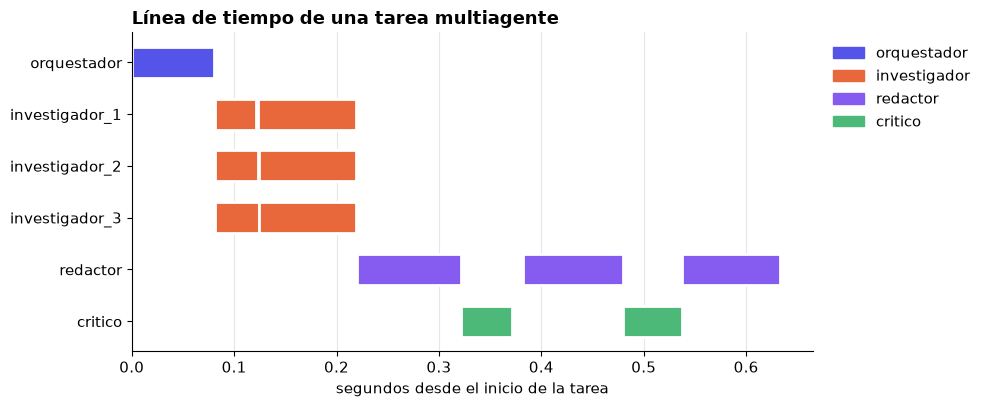

In [44]:
# Paleta institucional Icesi (validada para daltonismo en este orden)
COLORES_ROL = {"orquestador": "#5454e9", "investigador": "#e9683b", "redactor": "#865cf0",
               "critico": "#4cb979", "unico": "#5454e9", "router": "#865cf0", "juez": "#88898c"}
plt.rcParams.update({"axes.spines.top": False, "axes.spines.right": False, "axes.grid": True,
                     "grid.color": "#e6e6e6", "grid.linewidth": 0.8, "axes.axisbelow": True,
                     "font.size": 11, "axes.titleweight": "bold", "axes.titlelocation": "left"})

def costo_por_rol(run_id: str) -> pd.DataFrame:
    df = trazas_df().query("run_id == @run_id")
    t = df.groupby("rol").agg(llamadas=("agente", "size"), tokens_entrada=("tokens_entrada", "sum"),
                             tokens_salida=("tokens_salida", "sum"), costo_usd=("costo_usd", "sum"))
    t["% costo"] = (100 * t["costo_usd"] / t["costo_usd"].sum()).round(1)
    return t.sort_values("costo_usd", ascending=False)

def grafica_gantt(run_id: str, titulo: str):
    df = trazas_df().query("run_id == @run_id").copy()
    t0 = df["inicio"].min()
    df["ini"], df["dur"] = df["inicio"] - t0, df["fin"] - df["inicio"]
    agentes = list(dict.fromkeys(df["agente"]))
    fig, ax = plt.subplots(figsize=(10, 0.5 * len(agentes) + 1.2))
    for _, f in df.iterrows():
        ax.barh(agentes.index(f["agente"]), f["dur"], left=f["ini"], height=0.6,
                color=COLORES_ROL.get(f["rol"], "#5454e9"), edgecolor="white", linewidth=2)
    ax.set_yticks(range(len(agentes)), agentes)
    ax.invert_yaxis()
    ax.set_xlabel("segundos desde el inicio de la tarea")
    ax.set_title(titulo)
    roles = list(dict.fromkeys(df["rol"]))
    ax.legend(handles=[plt.Rectangle((0, 0), 1, 1, color=COLORES_ROL[r]) for r in roles], labels=roles,
              loc="upper left", bbox_to_anchor=(1.01, 1), frameon=False)
    ax.grid(axis="y", visible=False)
    plt.tight_layout()
    plt.show()

display(costo_por_rol(r_multi["run_id"]))
grafica_gantt(r_multi["run_id"], "Línea de tiempo de una tarea multiagente")

In [45]:
def indicadores_coordinacion(run_id: str, docs: list) -> dict:
    df = trazas_df().query("run_id == @run_id")
    total = df["costo_usd"].sum() or 1e-12
    coord = df[df["rol"].isin(["orquestador", "critico", "router"])]["costo_usd"].sum()
    por_doc = pd.Series([d for _, d in docs]).value_counts() if docs else pd.Series(dtype=int)
    repetidos = int((por_doc - 1).clip(lower=0).sum())
    return {"llamadas": len(df),
            "% costo en coordinación": round(100 * coord / total, 1),
            "documentos consultados": len(docs),
            "% consultas repetidas": round(100 * repetidos / max(1, len(docs)), 1)}

pd.DataFrame({"A · agente único": indicadores_coordinacion(r_unico["run_id"], r_unico["docs"]),
              "B · multiagente": indicadores_coordinacion(r_multi["run_id"], r_multi["docs"])})

,A · agente único,B · multiagente
llamadas,3.0,12.0
% costo en coordinación,0.0,22.4
documentos consultados,6.0,9.0
% consultas repetidas,50.0,66.7


## 7. Evaluación

Una sola pregunta no basta para comparar arquitecturas. Se usa un **dataset** de ocho preguntas, cada una con sus **puntos clave esperados** (la respuesta de referencia), y un **juez LLM** de otra familia que califica con una rúbrica:

| Criterio | Escala | Peso |
|---|---|---|
| Cobertura de puntos clave | fracción de puntos presentes | 60 % |
| Fidelidad (sin cifras inventadas, con citas) | 1 a 5 | 25 % |
| Claridad y recomendación explícita | 1 a 5 | 15 % |

El costo del juez se registra aparte (`config = "juez"`) para no mezclarlo con el costo del sistema evaluado.

In [46]:
DATASET = [
    {"pregunta": "¿Qué opción de expansión conviene más si la junta exige recuperar la inversión en menos de 24 meses?",
     "puntos": [{"texto": "La tienda online recupera la inversión en 14 meses", "termino": "14 meses"},
                {"texto": "La segunda tienda tarda 30 meses, por encima del límite", "termino": "30 meses"},
                {"texto": "La junta exige menos de 24 meses", "termino": "24 meses"},
                {"texto": "La tienda online requiere COP 95 millones", "termino": "95"}]},
    {"pregunta": "¿Qué canal de venta crece más y cuál deja mejor margen?",
     "puntos": [{"texto": "Domicilios por WhatsApp creció 41 %", "termino": "41"},
                {"texto": "La tienda tiene el mayor margen, 58 %", "termino": "58"},
                {"texto": "B2B tiene el menor margen, 31 %", "termino": "31"}]},
    {"pregunta": "¿La capacidad de la planta alcanza para la exportación a Chile?",
     "puntos": [{"texto": "El pedido mínimo es 1,2 toneladas al año", "termino": "1,2"},
                {"texto": "La planta trabaja al 72 % en un turno", "termino": "72"},
                {"texto": "Un segundo turno aumenta la capacidad 60 %", "termino": "60"},
                {"texto": "Se requiere certificación sanitaria de 6 meses", "termino": "certificacion"}]},
    {"pregunta": "¿Qué riesgos financieros y operativos enfrenta la empresa?",
     "puntos": [{"texto": "Tres clientes B2B concentran el 29 % de las ventas", "termino": "29"},
                {"texto": "La rotación de baristas es 35 % anual", "termino": "35"},
                {"texto": "El café verde subió 22 % en 2025", "termino": "22"}]},
    {"pregunta": "¿Hay evidencia de demanda para un modelo de suscripción?",
     "puntos": [{"texto": "El 63 % compraría una suscripción", "termino": "63"},
                {"texto": "Dos competidores ya venden con suscripción", "termino": "suscripcion"},
                {"texto": "Los domicilios tardan 3,2 días, principal queja", "termino": "3,2"}]},
    {"pregunta": "¿Puede la empresa financiar la segunda tienda sin crédito?",
     "puntos": [{"texto": "La segunda tienda cuesta COP 420 millones", "termino": "420"},
                {"texto": "La caja disponible es COP 380 millones: no alcanza", "termino": "380"},
                {"texto": "Hay un crédito preaprobado de COP 250 millones al 17 %", "termino": "17"}]},
    {"pregunta": "¿Cómo afecta el precio del café verde la rentabilidad del canal B2B?",
     "puntos": [{"texto": "El café verde es el 46 % del costo de producción", "termino": "46"},
                {"texto": "Su precio subió 22 % en 2025", "termino": "22"},
                {"texto": "B2B tiene margen de 31 % y precios fijos anuales", "termino": "31"}]},
    {"pregunta": "¿Qué debería mejorar primero en domicilios antes de lanzar una tienda online?",
     "puntos": [{"texto": "El tiempo de entrega promedio es 3,2 días", "termino": "3,2"},
                {"texto": "El margen de domicilios es 44 % después de envío", "termino": "44"},
                {"texto": "La tienda online requiere una persona de atención", "termino": "persona"}]},
]

INSTR_JUEZ = """Eres un evaluador estricto e imparcial. Compara la respuesta con los puntos clave esperados.
Para cada punto clave, en el mismo orden, indica si la respuesta lo contiene con el mismo dato (true/false).
Califica fidelidad de 1 a 5 (5 = toda cifra está respaldada y citada; 1 = hay cifras inventadas)
y claridad de 1 a 5 (5 = clara, breve y con una recomendación explícita).
Responde solo con JSON: {"puntos_presentes": [true, false, ...], "fidelidad": n, "claridad": n, "justificacion": "..."}"""

class Juicio(BaseModel):
    puntos_presentes: list[bool]
    fidelidad: int
    claridad: int
    justificacion: str = ""

async def juzgar(item: dict, respuesta: str) -> dict:
    run = {"id": "juez-" + uuid.uuid4().hex[:6], "config": "juez", "costo": 0.0, "tope": float("inf"), "docs": []}
    token = RUN_ACTUAL.set(run)
    try:
        if not respuesta:
            return {"cobertura": 0.0, "fidelidad": 1, "claridad": 1, "calidad": 0.0}
        entrada = (f"Pregunta: {item['pregunta']}\n<puntos>{json.dumps(item['puntos'], ensure_ascii=False)}</puntos>\n"
                   f"<respuesta>{respuesta}</respuesta>")
        juez = Agente("juez", MODELOS["juez"], INSTR_JUEZ, json_mode=True, max_tokens=400)
        j = parsear_json(await juez.ejecutar(entrada), Juicio)
        presentes = (j.puntos_presentes + [False] * len(item["puntos"]))[:len(item["puntos"])]
        cobertura = sum(presentes) / len(item["puntos"])
        calidad = 0.60 * cobertura + 0.25 * (j.fidelidad - 1) / 4 + 0.15 * (j.claridad - 1) / 4
        return {"cobertura": cobertura, "fidelidad": j.fidelidad, "claridad": j.claridad, "calidad": round(calidad, 3)}
    finally:
        RUN_ACTUAL.reset(token)

In [47]:
async def evaluar(cfg: Config, dataset=DATASET, repeticiones: int = 1) -> pd.DataFrame:
    items = [it for it in dataset for _ in range(repeticiones)]
    resultados = await asyncio.gather(*[ejecutar_tarea(cfg, it["pregunta"]) for it in items])
    juicios = await asyncio.gather(*[juzgar(it, r["respuesta"]) for it, r in zip(items, resultados)])
    filas = []
    tr = trazas_df()
    for r, j in zip(resultados, juicios):
        ind = indicadores_coordinacion(r["run_id"], r["docs"])
        t = tr[tr["run_id"] == r["run_id"]]
        filas.append({**{k: r[k] for k in ("run_id", "config", "pregunta", "exito", "latencia_s", "costo_usd")}, **j,
                      "llamadas": ind["llamadas"], "tokens": int(t["tokens_entrada"].sum() + t["tokens_salida"].sum()),
                      "pct_coordinacion": ind["% costo en coordinación"], "pct_repetidas": ind["% consultas repetidas"]})
    return pd.DataFrame(filas)

def resumen(df: pd.DataFrame) -> pd.DataFrame:
    g = df.groupby("config", sort=False)
    return pd.DataFrame({
        "calidad (0-1)": g["calidad"].mean().round(3),
        "cobertura": g["cobertura"].mean().round(2),
        "éxito %": (100 * g["exito"].mean()).round(0),
        "costo medio USD": g["costo_usd"].mean().round(5),
        "USD por 1.000 tareas": (1000 * g["costo_usd"].mean()).round(2),
        "latencia p50 s": g["latencia_s"].median().round(2),
        "latencia p95 s": g["latencia_s"].quantile(0.95).round(2),
        "llamadas": g["llamadas"].mean().round(1),
        "tokens": g["tokens"].mean().round(0),
        "% costo coordinación": g["pct_coordinacion"].mean().round(1),
        "% consultas repetidas": g["pct_repetidas"].mean().round(1),
    })

## 8. Experimento comparativo

Tres configuraciones sobre el mismo dataset:

- **A · agente único** con el modelo barato (baseline).
- **B · multiagente barato**: todos los roles con el modelo barato.
- **C · multiagente mixto**: orquestador, crítico y redactor con el modelo fuerte; investigadores con el barato.

Con modelos reales, conviene usar `repeticiones=2` o más: las respuestas varían entre ejecuciones y una sola corrida puede engañar.

In [48]:
CFG_MIXTO = Config("C · multiagente mixto", "multi", modelo_orquestador=MODELOS["fuerte"], modelo_redactor=MODELOS["fuerte"])
EXPERIMENTO = [CFG_UNICO, CFG_MULTI, CFG_MIXTO]

resultados = pd.concat([await evaluar(cfg, repeticiones=1) for cfg in EXPERIMENTO], ignore_index=True)
tabla = resumen(resultados)
tabla

,calidad (0-1),cobertura,éxito %,costo medio USD,USD por 1.000 tareas,latencia p50 s,latencia p95 s,llamadas,tokens,% costo coordinación,% consultas repetidas
config,,,,,,,,,,,
A · agente único,0.843,0.8,100.0,0.00006,0.06,0.36,0.41,3.0,1469.0,0.0,42.1
B · multiagente barato,0.843,0.8,100.0,0.00025,0.25,1.38,1.66,10.0,5581.0,20.2,52.8
C · multiagente mixto,0.843,0.8,100.0,0.00327,3.27,1.39,1.62,9.6,5231.0,42.2,52.8


### Frontera de Pareto: costo contra calidad

Una configuración está en la **frontera de Pareto** si ninguna otra es a la vez más barata y de mejor calidad. Las que quedan fuera de la frontera se pueden descartar.

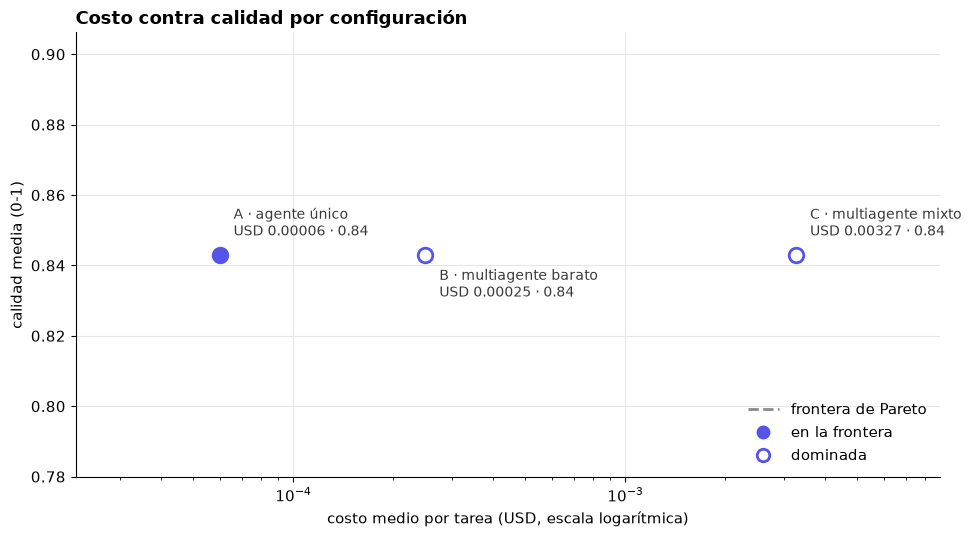

In [49]:
def frontera_pareto(tabla: pd.DataFrame) -> list[str]:
    puntos = tabla[["costo medio USD", "calidad (0-1)"]]
    return [n for n, (c, q) in puntos.iterrows()
            if not any((c2 <= c and q2 >= q) and (c2 < c or q2 > q) for c2, q2 in puntos.values)]

def grafica_pareto(tabla: pd.DataFrame, titulo="Costo contra calidad por configuración"):
    frontera = frontera_pareto(tabla)
    fig, ax = plt.subplots(figsize=(10, 5.5))
    f = tabla.loc[frontera].sort_values("costo medio USD")
    ax.plot(f["costo medio USD"], f["calidad (0-1)"], color="#88898c", linewidth=2, linestyle="--", zorder=1)
    orden = tabla.sort_values("costo medio USD")
    for k, (nombre, fila) in enumerate(orden.iterrows()):
        en_frontera = nombre in frontera
        ax.scatter(fila["costo medio USD"], fila["calidad (0-1)"], s=110, zorder=2,
                   color="#5454e9" if en_frontera else "white", edgecolor="#5454e9", linewidth=2)
        ax.annotate(f"{nombre}\nUSD {fila['costo medio USD']:.5f} · {fila['calidad (0-1)']:.2f}",
                    (fila["costo medio USD"], fila["calidad (0-1)"]), textcoords="offset points",
                    xytext=(10, 14 if k % 2 == 0 else -30), fontsize=10, color="#393939")
    ax.set_xscale("log")   # los costos difieren en órdenes de magnitud
    ax.set_xlabel("costo medio por tarea (USD, escala logarítmica)")
    ax.set_ylabel("calidad media (0-1)")
    ax.set_title(titulo)
    ax.margins(x=0.25, y=0.25)
    ax.legend(handles=[plt.Line2D([], [], color="#88898c", linestyle="--", linewidth=2),
                       plt.Line2D([], [], marker="o", color="#5454e9", linestyle="", markersize=9),
                       plt.Line2D([], [], marker="o", markerfacecolor="white", markeredgecolor="#5454e9",
                                  markeredgewidth=2, linestyle="", markersize=9)],
              labels=["frontera de Pareto", "en la frontera", "dominada"],
              frameon=False, loc="lower right")
    plt.tight_layout()
    plt.show()
    return frontera

_ = grafica_pareto(tabla)

**Preguntas para discutir con los resultados reales:**

- ¿Cuánto mejora la calidad B frente a A, y cuántas veces más cuesta?
- ¿En qué preguntas gana el multiagente? (pista: las que combinan varios documentos).
- ¿Qué parte del costo de B se va en coordinación? ¿Vale la pena el crítico?
- ¿El modelo fuerte de C cambia la calidad lo suficiente para justificar su precio?

El resultado puede sorprender, y ese es justamente el punto del experimento: la arquitectura se elige con datos, no por intuición.

In [50]:
# Detalle por pregunta: dónde gana cada arquitectura
resultados.pivot_table(index="pregunta", columns="config", values="calidad", sort=False).round(2)

config,A · agente único,B · multiagente barato,C · multiagente mixto
pregunta,,,
¿Qué opción de expansión conviene más si la junta exige recuperar la inversión en menos de 24 meses?,0.81,0.81,0.81
¿Qué canal de venta crece más y cuál deja mejor margen?,0.96,0.96,0.96
¿La capacidad de la planta alcanza para la exportación a Chile?,0.96,0.96,0.96
¿Qué riesgos financieros y operativos enfrenta la empresa?,0.96,0.96,0.96
¿Hay evidencia de demanda para un modelo de suscripción?,0.96,0.96,0.96
¿Puede la empresa financiar la segunda tienda sin crédito?,0.56,0.56,0.56
¿Cómo afecta el precio del café verde la rentabilidad del canal B2B?,0.96,0.96,0.96
¿Qué debería mejorar primero en domicilios antes de lanzar una tienda online?,0.56,0.56,0.56


## 9. Optimización de costos

Cinco palancas, de la más simple a la más estructural:

| Palanca | Qué hace | Dónde está en el código |
|---|---|---|
| Compresión de contexto | Los investigadores entregan resúmenes más cortos al redactor | `palabras_resumen` |
| Parada temprana | Menos rondas del crítico | `max_rondas_critico` |
| Menos paralelismo | Menos subtareas e investigadores | `max_subtareas` |
| Enrutamiento | Las preguntas simples van al agente único; las complejas, al equipo | `sistema_router` |
| Caché de prompts | Los proveedores cobran menos por prefijos repetidos | columna `tokens_cache` |

Primero se implementa el **router** (otro patrón de la clase): un clasificador barato decide qué arquitectura usar.

In [51]:
INSTR_ROUTER = """Clasifica la pregunta según cuánta evidencia requiere.
"simple": se responde con uno o dos documentos de un mismo tema.
"compleja": requiere combinar varios temas (finanzas, operación, clientes, riesgos).
Responde solo con JSON: {"complejidad": "simple"} o {"complejidad": "compleja"}"""

class Ruta(BaseModel):
    complejidad: str

async def sistema_router(pregunta: str, cfg: Config) -> str:
    router = Agente("router", cfg.modelo_trabajador, INSTR_ROUTER, json_mode=True, max_tokens=50)
    try:
        ruta = parsear_json(await router.ejecutar(pregunta), Ruta).complejidad
    except (ValueError, ValidationError):
        ruta = "compleja"
    return await (sistema_multiagente if ruta == "compleja" else sistema_agente_unico)(pregunta, cfg)

SISTEMAS["router"] = sistema_router

CFG_OPTIMIZADO = Config("D · multiagente optimizado", "multi", max_subtareas=2, max_rondas_critico=1, palabras_resumen=80)
CFG_ROUTER = Config("E · router", "router", max_subtareas=2, max_rondas_critico=1, palabras_resumen=80)

optim = pd.concat([await evaluar(cfg) for cfg in (CFG_OPTIMIZADO, CFG_ROUTER)], ignore_index=True)
resultados = pd.concat([resultados, optim], ignore_index=True)
tabla = resumen(resultados)
tabla

,calidad (0-1),cobertura,éxito %,costo medio USD,USD por 1.000 tareas,latencia p50 s,latencia p95 s,llamadas,tokens,% costo coordinación,% consultas repetidas
config,,,,,,,,,,,
A · agente único,0.843,0.80,100.0,0.00006,0.06,0.36,0.41,3.0,1469.0,0.0,42.1
B · multiagente barato,0.843,0.80,100.0,0.00025,0.25,1.38,1.66,10.0,5581.0,20.2,52.8
C · multiagente mixto,0.843,0.80,100.0,0.00327,3.27,1.39,1.62,9.6,5231.0,42.2,52.8
D · multiagente optimizado,0.731,0.61,100.0,0.00015,0.15,1.04,1.12,7.6,3411.0,18.8,35.4
E · router,0.775,0.69,100.0,0.00011,0.11,0.65,0.87,6.2,2497.0,13.1,39.2


,Δ costo %,Δ calidad (puntos),Δ latencia p50 %
D · multiagente optimizado,-40.0,-0.112,-24.6
E · router,-56.0,-0.068,-52.9


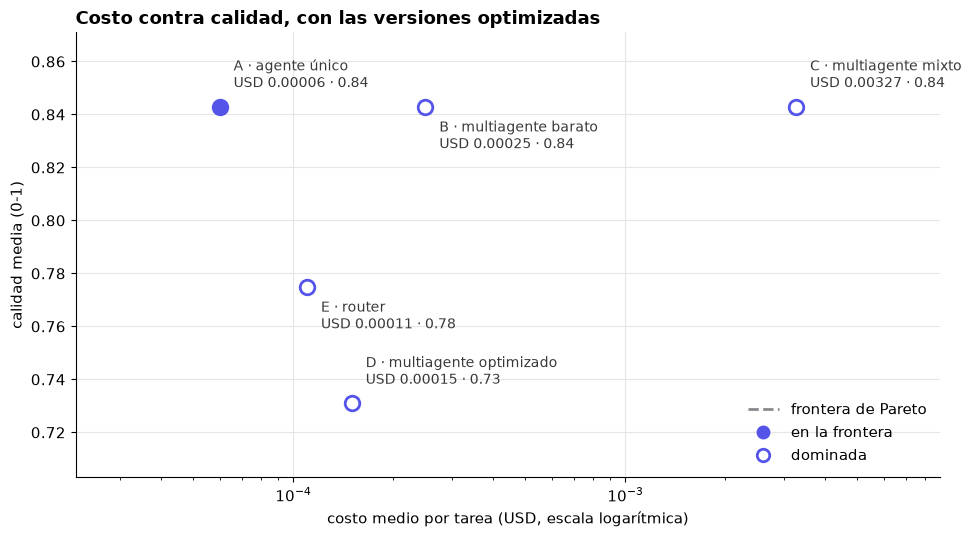

In [52]:
# Antes y después frente a B (multiagente sin optimizar)
base = tabla.loc["B · multiagente barato"]
comparacion = pd.DataFrame({
    nombre: {"Δ costo %": round(100 * (tabla.loc[nombre, "costo medio USD"] / base["costo medio USD"] - 1), 1),
             "Δ calidad (puntos)": round(tabla.loc[nombre, "calidad (0-1)"] - base["calidad (0-1)"], 3),
             "Δ latencia p50 %": round(100 * (tabla.loc[nombre, "latencia p50 s"] / base["latencia p50 s"] - 1), 1)}
    for nombre in ["D · multiagente optimizado", "E · router"]}).T
display(comparacion)
_ = grafica_pareto(tabla, "Costo contra calidad, con las versiones optimizadas")

### Caché de prompts

Muchos proveedores cobran menos (o nada) por los tokens de entrada que repiten un prefijo ya visto; DeepSeek, por ejemplo, lo hace de forma automática. Para aprovecharlo, lo **fijo** (instrucciones, herramientas, documentos estables) va al inicio del prompt y lo **variable** (la pregunta) al final. La columna `tokens_cache` de las trazas muestra cuánto se reutilizó.

In [53]:
tr = trazas_df()
tr = tr[tr["config"].notna() & (tr["config"] != "juez")]
cache = tr.groupby("config", sort=False)[["tokens_entrada", "tokens_cache"]].sum()
cache["% entrada en caché"] = (100 * cache["tokens_cache"] / cache["tokens_entrada"].clip(lower=1)).round(1)
cache

,tokens_entrada,tokens_cache,% entrada en caché
config,,,
A · agente único,11489,0,0.0
B · multiagente barato,43079,0,0.0
C · multiagente mixto,34477,0,0.0
D · multiagente optimizado,22547,0,0.0
E · router,16822,0,0.0


### Costo total de la sesión

Incluye al juez. Sirve para calcular cuánto crédito necesita el grupo para correr el notebook.

In [ ]:
tr = trazas_df()
total = tr.groupby(tr["config"].fillna("demo"))["costo_usd"].agg(["count", "sum"]).rename(
    columns={"count": "llamadas", "sum": "USD"})
total.loc["TOTAL"] = total.sum()
print("Costos reales reportados por OpenRouter")
total.round(5)

In [56]:
# Guardar resultados para analizarlos después o compararlos entre grupos
resultados.to_csv("resultados_experimento.csv", index=False)
trazas_df().to_csv("trazas.csv", index=False)
print("Archivos guardados: resultados_experimento.csv, trazas.csv")

Archivos guardados: resultados_experimento.csv, trazas.csv


## 10. Ejercicios

1. **Verificador de hechos.** Agregar un agente que revise, cita por cita, que cada cifra de la respuesta aparezca en el documento citado. Medir cuánto sube la fidelidad y cuánto cuesta.
2. **Cambio de patrón.** Reemplazar el orquestador por un **pipeline** fijo (ventas → costos → riesgos → redacción). ¿Qué pasa con la latencia, ahora que nada corre en paralelo?
3. **Reto de costo.** Lograr una configuración que cueste al menos 40 % menos que B sin perder más de 0,05 de calidad. Se puede tocar cualquier parámetro de `Config`, los prompts o los modelos.
4. **Robustez.** Hacer que `buscar_en_corpus` falle aleatoriamente el 20 % de las veces. ¿Qué arquitectura degrada mejor? ¿Qué cambia en la tasa de éxito?
5. **Juez sesgado.** Repetir la evaluación usando como juez el mismo modelo de los trabajadores. ¿Cambian las calificaciones?
6. **Ruido de medición.** Correr B con `repeticiones=3`. ¿Cuánto varían la calidad y el costo entre corridas? ¿Las diferencias entre configuraciones siguen siendo claras?

## 11. Del código propio a los frameworks

Lo construido aquí corresponde a piezas que los frameworks ofrecen ya hechas:

| Concepto en este notebook | LangGraph | OpenAI Agents SDK | Claude Agent SDK | CrewAI |
|---|---|---|---|---|
| `Agente` con su ciclo | nodo con `ToolNode` | `Agent` + `Runner` | agente con herramientas | `Agent` |
| Orquestador y flujo | grafo de estados | *handoffs* | subagentes | `Crew` con proceso jerárquico |
| Paralelismo | ramas del grafo | `asyncio` | subagentes en paralelo | tareas asíncronas |
| `TRAZAS` | LangSmith | *tracing* integrado | *hooks* | callbacks |
| `Config` | configuración del grafo | `RunConfig` | opciones del agente | parámetros del `Crew` |

Un framework ahorra código, pero **no reemplaza la medición**: las preguntas de costo, calidad y coordinación de este notebook aplican igual con cualquiera de ellos.